In [47]:
import os
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms
from google.colab import files

# Set device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Running on device: {device}")

Running on device: cuda


In [48]:
# 1. Architecture Definition
class PCSAModule(nn.Module):
    def __init__(self, in_channels, reduction=16):
        super(PCSAModule, self).__init__()
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)

        self.fc = nn.Sequential(
            nn.Linear(in_channels, in_channels // reduction, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(in_channels // reduction, in_channels, bias=False)
        )

        self.conv_spatial_3 = nn.Conv2d(2, 1, kernel_size=3, padding=1, bias=False)
        self.conv_spatial_5 = nn.Conv2d(2, 1, kernel_size=5, padding=2, bias=False)

    def forward(self, x):
        b, c, _, _ = x.size()
        y_avg = self.fc(self.avg_pool(x).view(b, c)).view(b, c, 1, 1)
        y_max = self.fc(self.max_pool(x).view(b, c)).view(b, c, 1, 1)
        channel_weights = torch.sigmoid(y_avg + y_max)
        x_out = x * channel_weights

        max_out, _ = torch.max(x_out, dim=1, keepdim=True)
        avg_out = torch.mean(x_out, dim=1, keepdim=True)
        spatial_in = torch.cat([max_out, avg_out], dim=1)

        spatial_weights_3 = self.conv_spatial_3(spatial_in)
        spatial_weights_5 = self.conv_spatial_5(spatial_in)
        spatial_weights = torch.sigmoid(spatial_weights_3 + spatial_weights_5)

        return x_out * spatial_weights


class PCSA_KidneyNeXt_Block(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super(PCSA_KidneyNeXt_Block, self).__init__()
        self.max_pool = nn.MaxPool2d(kernel_size=3, stride=stride, padding=1)
        self.avg_pool = nn.AvgPool2d(kernel_size=3, stride=stride, padding=1)

        self.g_conv1 = nn.Conv2d(in_channels, in_channels, kernel_size=3, stride=stride, padding=1, groups=in_channels, bias=False)
        self.g_conv2 = nn.Conv2d(in_channels, in_channels, kernel_size=5, stride=stride, padding=2, groups=in_channels, bias=False)

        concat_channels = in_channels * 4
        self.compress_conv = nn.Conv2d(concat_channels, out_channels, kernel_size=1, bias=False)
        self.bn = nn.BatchNorm2d(out_channels)
        self.gelu = nn.GELU()

        self.pcsa = PCSAModule(out_channels)

        self.shortcut = nn.Sequential()
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(out_channels)
            )

    def forward(self, x):
        p_max = self.max_pool(x)
        p_avg = self.avg_pool(x)
        g1 = self.g_conv1(x)
        g2 = self.g_conv2(x)

        out = torch.cat([p_max, p_avg, g1, g2], dim=1)
        out = self.compress_conv(out)
        out = self.bn(out)
        out = self.gelu(out)
        out = self.pcsa(out)
        out = out + self.shortcut(x)
        return out


class PCSA_KidneyNeXt(nn.Module):
    def __init__(self, num_classes=4):
        super(PCSA_KidneyNeXt, self).__init__()
        self.stem_conv1 = nn.Conv2d(3, 96, kernel_size=4, stride=4, padding=0, bias=False)
        self.stem_conv2 = nn.Conv2d(3, 96, kernel_size=4, stride=4, padding=0, bias=False)
        self.stem_bn = nn.BatchNorm2d(96)
        self.stem_gelu = nn.GELU()

        self.stage1 = PCSA_KidneyNeXt_Block(in_channels=96, out_channels=96, stride=1)
        self.stage2 = PCSA_KidneyNeXt_Block(in_channels=96, out_channels=192, stride=2)
        self.stage3 = PCSA_KidneyNeXt_Block(in_channels=192, out_channels=384, stride=2)
        self.stage4 = PCSA_KidneyNeXt_Block(in_channels=384, out_channels=768, stride=2)

        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))
        self.classifier = nn.Linear(768, num_classes)

    def forward(self, x):
        s1 = self.stem_conv1(x)
        s2 = self.stem_conv2(x)
        out = (s1 + s2) / 2.0
        out = self.stem_gelu(self.stem_bn(out))

        out = self.stage1(out)
        out = self.stage2(out)
        out = self.stage3(out)
        out = self.stage4(out)

        out = self.global_pool(out)
        out = torch.flatten(out, 1)
        out = self.classifier(out)
        return out

# 2. Instantiate and Load Saved Checkpoint
model = PCSA_KidneyNeXt(num_classes=4).to(device)

# Upload model weights file directly or specify the path
weights_path = 'best_pcsa_kidneynext_60epochs_AUGMENTED.pth'

if not os.path.exists(weights_path):
    print("Please upload your weights file:")
    uploaded = files.upload()
    weights_path = list(uploaded.keys())[0]

model.load_state_dict(torch.load(weights_path, map_location=device))
model.eval()
print(f"✅ Loaded weights successfully from: {weights_path}")

✅ Loaded weights successfully from: best_pcsa_kidneynext_60epochs_AUGMENTED.pth


In [49]:
class PreciseGradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None

        self.target_layer.register_forward_hook(self._save_activation)
        self.target_layer.register_full_backward_hook(self._save_gradient)

    def _save_activation(self, module, input, output):
        self.activations = output.detach()

    def _save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()

    def generate_heatmap(self, input_tensor, target_class=None):
        self.model.eval()
        output = self.model(input_tensor)

        if target_class is None:
            target_class = torch.argmax(output, dim=1).item()

        self.model.zero_grad()
        score = output[0, target_class]
        score.backward()

        weights = torch.mean(self.gradients, dim=(2, 3), keepdim=True)
        cam = torch.sum(weights * self.activations, dim=1, keepdim=True)
        cam = F.relu(cam)
        cam = cam.squeeze().cpu().numpy()

        # --- SHARPENING FILTER ---
        # Raise to the power of 3 to suppress weak background signals
        # and heavily emphasize the highest confidence pixels (the stone)
        cam = np.power(cam, 3)

        cam = cam - np.min(cam)
        if np.max(cam) != 0:
            cam = cam / np.max(cam)

        # Hard thresholding: wipe out any heatmap colors below 30% intensity
        cam[cam < 0.3] = 0

        return cam, output, target_class

# Initialize targeting stage3 instead of stage4 for double the resolution
grad_cam = PreciseGradCAM(model, target_layer=model.stage3)
print("✅ High-Precision Grad-CAM Engine Ready.")

✅ High-Precision Grad-CAM Engine Ready.


In [50]:
import torch
from PIL import Image
from google.colab import files
from torchvision import transforms

# Define class names and standard transformations for the classifier
class_names = ['Cyst', 'Normal', 'Stone', 'Tumor']
transform_pipeline = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

print("Upload your raw manually cropped photo (e.g., from Photopea):")
uploaded = files.upload()
img_filename = list(uploaded.keys())[0]

# 1. Load the raw cropped image directly into PIL (NO math filters)
raw_cropped_pil = Image.open(img_filename).convert('RGB')

# 2. Assign to the 'cropped_image' variable so downstream Grad-CAM cells work perfectly
cropped_image = raw_cropped_pil

# 3. Generate the input tensor for the Grad-CAM/Classifier model
input_tensor = transform_pipeline(cropped_image).unsqueeze(0).to(device)

print(f"✅ Raw image '{img_filename}' loaded safely! Tensor Shape: {input_tensor.shape}")
print("You can now run the Grad-CAM cell and the YOLO cell directly after this.")

Upload your raw manually cropped photo (e.g., from Photopea):


Saving 1 cropped .png to 1 cropped .png
✅ Raw image '1 cropped .png' loaded safely! Tensor Shape: torch.Size([1, 3, 224, 224])
You can now run the Grad-CAM cell and the YOLO cell directly after this.


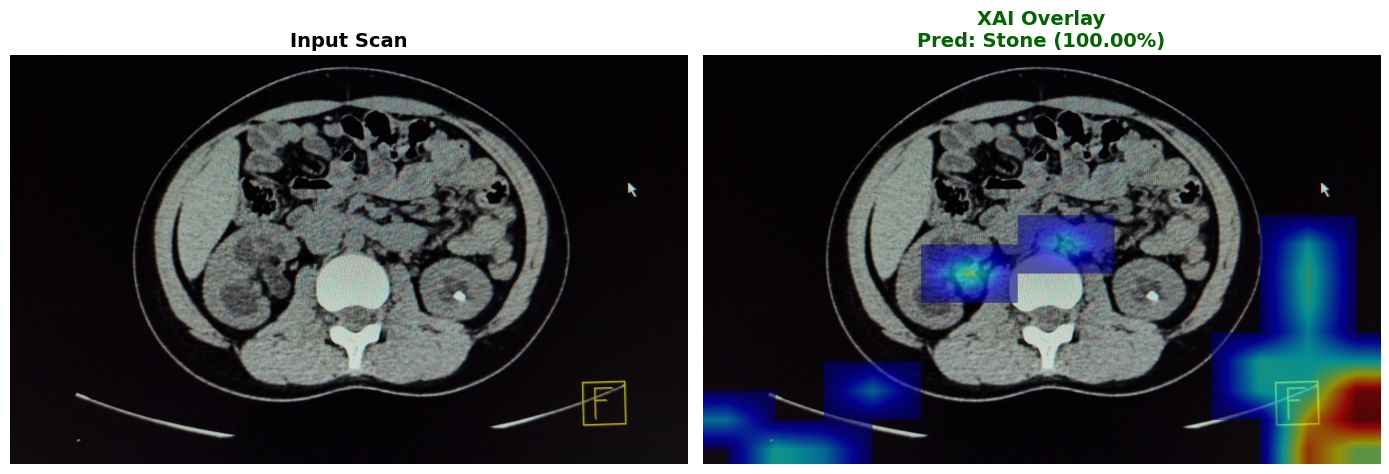


--- Diagnostic Prediction Probabilities ---
Class 0 (Cyst): 0.00%
Class 1 (Normal): 0.00%
Class 2 (Stone): 100.00%
Class 3 (Tumor): 0.00%


In [51]:
import numpy as np
import cv2
import torch.nn.functional as F
import matplotlib.pyplot as plt

# --- 1. Use the Image Already Loaded in Memory ---
# This grabs the 'cropped_image' and 'input_tensor' you just generated
raw_np = np.array(cropped_image)
h, w, _ = raw_np.shape


# --- 2. Run Precise Grad-CAM & Model Inference ---
heatmap, logits, predicted_class_idx = grad_cam.generate_heatmap(input_tensor)

probabilities = F.softmax(logits, dim=1).squeeze().detach().cpu().numpy()
predicted_class_name = class_names[predicted_class_idx]
confidence = probabilities[predicted_class_idx] * 100


# --- 3. Map Heatmap Back to Original Dimensions ---
# Stretch the 224x224 heatmap back to the image's rectangular dimensions
heatmap_resized = cv2.resize(heatmap, (w, h))

# Generate Colorized Heatmap & Blend
heatmap_colored = cv2.applyColorMap(np.uint8(255 * heatmap_resized), cv2.COLORMAP_JET)
heatmap_colored = cv2.cvtColor(heatmap_colored, cv2.COLOR_BGR2RGB)

mask = heatmap_resized > 0
overlay = raw_np.copy()
alpha = 0.55
overlay[mask] = cv2.addWeighted(raw_np, 1 - alpha, heatmap_colored, alpha, 0)[mask]


# --- 4. Display Diagnostic Results (Activation Map Removed) ---
# Changed to a 1x2 grid for a cleaner side-by-side view
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(raw_np)
axes[0].set_title("Input Scan", fontsize=14, fontweight='bold')
axes[0].axis('off')

axes[1].imshow(overlay)
axes[1].set_title(f"XAI Overlay\nPred: {predicted_class_name} ({confidence:.2f}%)", fontsize=14, fontweight='bold', color='darkgreen')
axes[1].axis('off')

plt.tight_layout()
plt.show()

print("\n--- Diagnostic Prediction Probabilities ---")
for idx, name in enumerate(class_names):
    print(f"Class {idx} ({name}): {probabilities[idx]*100:.2f}%")

🩺 Running Stage 1: Global Pathology Triage...
✅ Triage Complete. Primary Pathology: Stone (100.00%)
🔄 Routing to Specialized STONE Segmentation Expert...


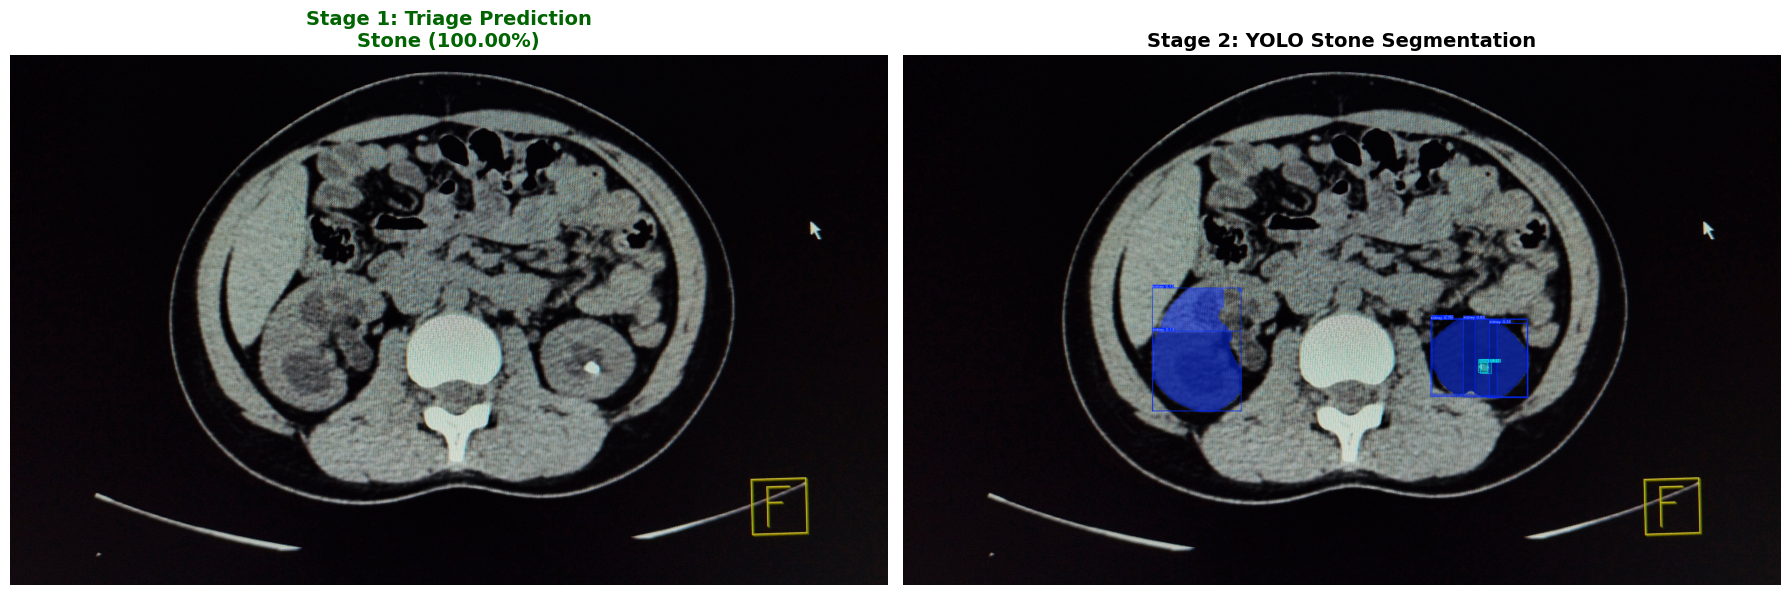


🔍 Isolated Pathology ROIs:


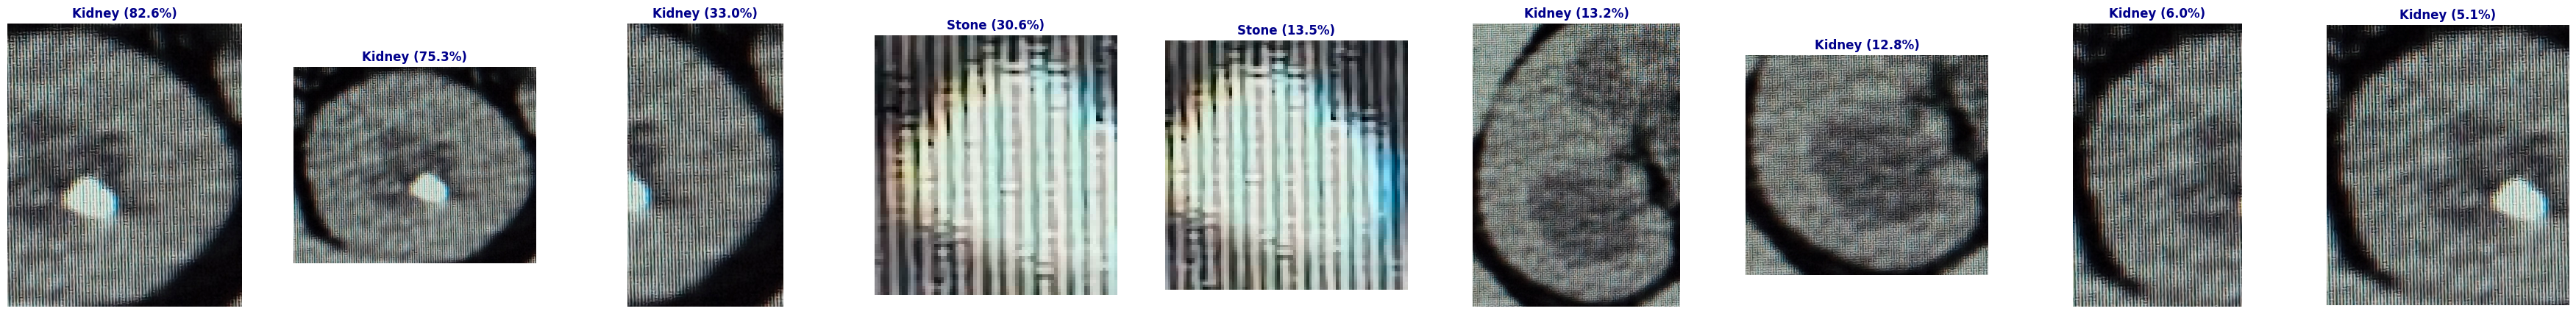


 🏥 STONE CLINICAL QUANTITATIVE REPORT
  Finding Confidence Bounding Box (LxW)    Est. Area
Kidney #1      82.6%   255.5 x 313.6 mm  60731.1 mm²
Kidney #2      75.3%   387.8 x 310.1 mm  88812.0 mm²
Kidney #3      33.0%   154.7 x 298.2 mm  31488.9 mm²
 Stone #4      30.6%     35.7 x 39.9 mm   1048.6 mm²
 Stone #5      13.5%     42.7 x 44.8 mm   1230.4 mm²
Kidney #6      13.2%   355.6 x 493.5 mm 123651.7 mm²
Kidney #7      12.8%   354.2 x 319.9 mm  86982.1 mm²
Kidney #8       6.0%   172.9 x 303.8 mm  41366.5 mm²
Kidney #9       5.1%   261.1 x 305.2 mm  64710.6 mm²


In [52]:
import torch
import torch.nn.functional as F
from ultralytics import YOLO
from PIL import Image
import numpy as np
import cv2
import matplotlib.pyplot as plt
import pandas as pd
import os

# --- 1. Load Raw Image & Prepare Tensor ---
img_filename = '1 cropped .png'
raw_cropped_pil = Image.open(img_filename).convert('RGB')
raw_np = np.array(raw_cropped_pil)

# Ensure transform_pipeline is applied to create the 224x224 tensor for the classifier
input_tensor = transform_pipeline(raw_cropped_pil).unsqueeze(0).to(device)


# --- 2. STAGE 1: Global Triage (PCSA-KidneyNeXt Classifier) ---
print("🩺 Running Stage 1: Global Pathology Triage...")
model.eval()
with torch.no_grad():
    logits = model(input_tensor)

probabilities = F.softmax(logits, dim=1).squeeze().cpu().numpy()
predicted_class_idx = np.argmax(probabilities)
predicted_class_name = class_names[predicted_class_idx]
confidence = probabilities[predicted_class_idx] * 100

print(f"✅ Triage Complete. Primary Pathology: {predicted_class_name} ({confidence:.2f}%)")


# --- 3. DYNAMIC MODEL ROUTING ---
seg_weights_path = None
if predicted_class_name.lower() == 'tumor':
    seg_weights_path = 'best_tumor_specialized.pt'
    print("🔄 Routing to Specialized TUMOR Segmentation Expert...")
elif predicted_class_name.lower() == 'stone':
    seg_weights_path = 'best_stone_specialized.pt'
    print("🔄 Routing to Specialized STONE Segmentation Expert...")
else:
    print(f"⚠️ Predicted {predicted_class_name}. No specialized segmentation required.")


# --- 4. STAGE 2: Specialized YOLO Segmentation ---
if seg_weights_path:
    # Dynamically load the correct weights based on the classifier's verdict
    dynamic_seg_model = YOLO(seg_weights_path)

    def run_dynamic_segmentation(pil_image, seg_model, conf_threshold=0.05, imgsz=640, pixel_spacing_mm=0.7):
        orig_bgr = cv2.cvtColor(np.array(pil_image), cv2.COLOR_RGB2BGR)

        results = seg_model.predict(source=orig_bgr, imgsz=imgsz, conf=conf_threshold, verbose=False)[0]
        plotted_bgr = results.plot(labels=True, boxes=True, masks=True, line_width=2)
        plotted_rgb = cv2.cvtColor(plotted_bgr, cv2.COLOR_BGR2RGB)

        clinical_report = []
        zoomed_rois = []
        target_count = 0

        if results.boxes is not None and results.masks is not None:
            boxes = results.boxes.cpu().numpy()
            masks = results.masks.data.cpu().numpy()
            names = results.names

            for box, mask in zip(boxes, masks):
                cls_name = names.get(int(box.cls[0]), "Unknown").lower()
                target_count += 1
                conf = float(box.conf[0])

                x1, y1, x2, y2 = map(int, box.xyxy[0])
                width_mm = (x2 - x1) * pixel_spacing_mm
                height_mm = (y2 - y1) * pixel_spacing_mm

                mask_resized = cv2.resize(mask, (orig_bgr.shape[1], orig_bgr.shape[0]), interpolation=cv2.INTER_NEAREST)
                mask_binary = (mask_resized > 0.5).astype(np.uint8)

                contours, _ = cv2.findContours(mask_binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
                real_area_mm2 = 0
                if contours:
                    largest_contour = max(contours, key=cv2.contourArea)
                    real_area_mm2 = cv2.contourArea(largest_contour) * (pixel_spacing_mm ** 2)

                pad = 15
                h, w = raw_np.shape[:2]
                cx1, cy1 = max(0, x1 - pad), max(0, y1 - pad)
                cx2, cy2 = min(w, x2 + pad), min(h, y2 + pad)
                zoomed_rois.append((raw_np[cy1:cy2, cx1:cx2], cls_name, conf))

                clinical_report.append({
                    "Finding": f"{cls_name.capitalize()} #{target_count}",
                    "Confidence": f"{conf * 100:.1f}%",
                    "Bounding Box (LxW)": f"{width_mm:.1f} x {height_mm:.1f} mm",
                    "Est. Area": f"{real_area_mm2:.1f} mm²"
                })

        return plotted_rgb, zoomed_rois, clinical_report

    # Execute the segmentation
    advanced_overlay, detected_rois, clinical_report = run_dynamic_segmentation(raw_cropped_pil, dynamic_seg_model)

    # --- 5. Visualizations ---
    fig = plt.figure(figsize=(18, 8))

    ax1 = fig.add_subplot(1, 2, 1)
    ax1.imshow(raw_np)
    ax1.set_title(f"Stage 1: Triage Prediction\n{predicted_class_name} ({confidence:.2f}%)", fontsize=14, fontweight='bold', color='darkgreen')
    ax1.axis('off')

    ax2 = fig.add_subplot(1, 2, 2)
    ax2.imshow(advanced_overlay)
    ax2.set_title(f"Stage 2: YOLO {predicted_class_name.capitalize()} Segmentation", fontsize=14, fontweight='bold')
    ax2.axis('off')

    plt.tight_layout()
    plt.show()

    # Display Target ROIs
    if detected_rois:
        print("\n🔍 Isolated Pathology ROIs:")
        fig_roi, axes = plt.subplots(1, len(detected_rois), figsize=(5 * len(detected_rois), 5))
        if len(detected_rois) == 1:
            axes = [axes]
        for ax, (roi_img, cls_name, conf) in zip(axes, detected_rois):
            ax.imshow(roi_img)
            ax.set_title(f"{cls_name.capitalize()} ({conf*100:.1f}%)", fontweight='bold', color='darkblue')
            ax.axis('off')
        plt.show()
    else:
        print(f"\n✅ YOLO detected no distinct boundaries at a 5% threshold.")

    # Print Clinical Report
    print("\n" + "="*70)
    print(f" 🏥 {predicted_class_name.upper()} CLINICAL QUANTITATIVE REPORT")
    print("="*70)
    if len(clinical_report) > 0:
        print(pd.DataFrame(clinical_report).to_string(index=False))
    else:
        print("⚠️ Report is empty.")
    print("="*70)